In [1]:
!pip install -q transformers datasets

In [2]:
import math, random, time
import torch

import matplotlib.pyplot as plt
import numpy as np
from transformers import AutoModelForCausalLM, AutoTokenizer

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


In [3]:
model_name = "EleutherAI/pythia-160m-deduped"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForCausalLM.from_pretrained(model_name, torch_dtype=torch.float32).to(device)
model.eval()

for p in model.parameters():
    p.requires_grad_(False)

config.json:   0%|          | 0.00/569 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/396 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  375MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [4]:
model_config = model.config
model_config.num_hidden_layers
model.config.model_type

'gpt_neox'

In [5]:
model.gpt_neox.layers

ModuleList(
  (0-11): 12 x GPTNeoXLayer(
    (input_layernorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
    (post_attention_layernorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
    (post_attention_dropout): Dropout(p=0.0, inplace=False)
    (post_mlp_dropout): Dropout(p=0.0, inplace=False)
    (attention): GPTNeoXAttention(
      (query_key_value): Linear(in_features=768, out_features=2304, bias=True)
      (dense): Linear(in_features=768, out_features=768, bias=True)
    )
    (mlp): GPTNeoXMLP(
      (dense_h_to_4h): Linear(in_features=768, out_features=3072, bias=True)
      (dense_4h_to_h): Linear(in_features=3072, out_features=768, bias=True)
      (act): GELUActivation()
    )
  )
)

In [6]:
model.gpt_neox.final_layer_norm

LayerNorm((768,), eps=1e-05, elementwise_affine=True)

In [7]:
model.config.architectures

['GPTNeoXForCausalLM']

In [8]:
model_config.num_attention_heads
model_config.vocab_size
model_config.hidden_size

768

In [9]:
model.gpt_neox

GPTNeoXModel(
  (embed_in): Embedding(50304, 768)
  (emb_dropout): Dropout(p=0.0, inplace=False)
  (layers): ModuleList(
    (0-11): 12 x GPTNeoXLayer(
      (input_layernorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (post_attention_layernorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (post_attention_dropout): Dropout(p=0.0, inplace=False)
      (post_mlp_dropout): Dropout(p=0.0, inplace=False)
      (attention): GPTNeoXAttention(
        (query_key_value): Linear(in_features=768, out_features=2304, bias=True)
        (dense): Linear(in_features=768, out_features=768, bias=True)
      )
      (mlp): GPTNeoXMLP(
        (dense_h_to_4h): Linear(in_features=768, out_features=3072, bias=True)
        (dense_4h_to_h): Linear(in_features=3072, out_features=768, bias=True)
        (act): GELUActivation()
      )
    )
  )
  (final_layer_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  (rotary_emb): GPTNeoXRotaryEmbedding()
)

In [10]:
def get_parts(model):
  if hasattr(model, "gpt_neox"):
    print('ran model type gpt_neox')
    blocks, final_layer = model.gpt_neox.layers, model.gpt_neox.final_layer_norm
  elif hasattr(model, "transformer") and hasattr(model.transformer, "h"):
    print('ran_this2')
    blocks, final_layer = model.transformer.h, model.transformer.ln_f
  else:
    print("No model found")

  unembed = model.get_output_embeddings()
  return blocks, final_layer, unembed

blocks, final_layer, unembed = get_parts(model)
L = len(blocks)
d_model = model.config.hidden_size
print(len(blocks), final_layer, unembed)

ran model type gpt_neox
12 LayerNorm((768,), eps=1e-05, elementwise_affine=True) Linear(in_features=768, out_features=50304, bias=False)


In [11]:
# @torch.no_grad()
# def run_with_residuals(model, input_ids):
#     # Returns (residuals, final_logits). residuals: list of L tensors [B, T, d]
#     residuals = []
#     def pre_hook(module, args, kwargs):
#         h = args[0] if len(args) > 0 else kwargs["hidden_states"]
#         residuals.append(h.detach())
#     handles = [b.register_forward_pre_hook(pre_hook, with_kwargs=True) for b in blocks]
#     try:
#         out = model(input_ids=input_ids)
#     finally:
#         for hd in handles:
#             hd.remove()
#     assert len(residuals) == L
#     return residuals, out.logits.float()

# # quick check: one residual per block, each [batch, tokens, d_model]
# ids = torch.randint(0, model.config.vocab_size, (1, 16), device=device)
# res, logits = run_with_residuals(model, ids)
# print(len(res), "residuals of shape", tuple(res[0].shape))

In [12]:
@torch.no_grad()
def run_with_residuals(model, input_ids):
  residuals = []
  def save_hidden_state(module, args):
    residuals.append(args[0].detach())

  handles = [block.register_forward_pre_hook(save_hidden_state) for block in blocks]
  captured = {}

  def save_hidden_state2(module, args):
    # print("Layer:", module)
    # print("Number of inputs:", len(args))
    # print("Input shape:", args[0].shape)
    captured["h_L"] = args[0]



  hk = final_layer.register_forward_pre_hook(save_hidden_state2)

  #print(len(handles), handles)
  output = model(input_ids=input_ids)
  for handle in handles:
    handle.remove()

  hk.remove()

  def logit_lens(h):
    return unembed(final_layer(h))

  print('Check',(logit_lens(captured["h_L"]) - output.logits).abs().max().item())
  return residuals, output.logits.float()

In [13]:
ids = torch.randint(0, model.config.vocab_size, (1, 16), device=device)
res, logits = run_with_residuals(model, ids)
#print(len(res), "residuals of shape", tuple(res[0].shape))

Check 0.0


In [14]:
def logit_lens(h):
    return unembed(final_layer(h))

def show_top1_table(lens_fn, text, title):
    enc = tokenizer(text, return_tensors="pt").input_ids.to(device)
    res, final_logits = run_with_residuals(model, enc)
    toks = [tokenizer.decode([t]) for t in enc[0]]
    rows = []
    with torch.no_grad():
        for l, h in enumerate(res):
            top = lens_fn(h, l).argmax(-1)[0]
            rows.append((f"layer {l:2d}", [tokenizer.decode([t]) for t in top]))
        rows.append(("final   ", [tokenizer.decode([t]) for t in final_logits.argmax(-1)[0]]))
    print(title)
    print(toks)
    #print("input   :", " | ".join(repr(t) for t in toks))
    for name, preds in rows:
      print(name, preds)

PROMPT = "The capital of France is Paris, and the capital of Germany is"
show_top1_table(lambda h, l: logit_lens(h), PROMPT, "LOGIT LENS: top-1 next-token prediction per layer")

Check 0.0
LOGIT LENS: top-1 next-token prediction per layer
['The', ' capital', ' of', ' France', ' is', ' Paris', ',', ' and', ' the', ' capital', ' of', ' Germany', ' is']
layer  0 [' exclusive', ' bias', ' account', ' Gene', ' composed', 'i', ' reserve', ' deprivation', 'ft', ' bias', ' account', ' Ministry', ' composed']
layer  1 ['orems', ' petition', ' course', 'enne', ' therefore', 'ε', ' therefore', ' therefore', ' Examin', ' round', ' course', ' institution', ' therefore']
layer  2 ['orems', ' petition', ' course', ' courts', ' therefore', 'δ', ' therefore', ' therefore', ' Examin', ' itself', ' course', ' courts', ' therefore']
layer  3 [' comment', ' statement', ' course', ' courts', ' therefore', 'ian', ' however', ' therefore', ' courts', ' itself', ' course', ' courts', ' therefore']
layer  4 [' kinetics', ' round', ' course', ' courts', ' therefore', ' Hilton', ' however', ' therefore', ' latter', ' itself', ' course', ' courts', ' therefore']
layer  5 [' kinetics', ' ro

# **Tuned Lens**

In [18]:
class TunedLens(torch.nn.Module):
  def __init__(self, num_layers, d_model):
    super().__init__()
    self.translators = torch.nn.ModuleList([torch.nn.Linear(d_model, d_model) for _ in range(num_layers)])
    for t in self.translators:
      torch.nn.init.zeros_(t.weight)
      torch.nn.init.zeros_(t.bias)

  def transform(self, h, layer):
      return h + self.translators[layer](h)

  def forward(self, h, layer):
    return unembed(final_layer(self.transform(h, layer)))

tuned_lens = TunedLens(L, d_model).to(device)
print("trainable params:", sum(p.numel() for p in tuned_lens.parameters()) / 1e6, "M")

trainable params: 7.087104 M


In [19]:
from datasets import load_dataset

SEQ_LEN = 128

def make_chunks(split):
    ds = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split=split)
    text = "\n".join(t for t in ds["text"] if t.strip())
    ids = tokenizer(text, return_tensors="pt").input_ids[0]
    n = len(ids) // SEQ_LEN
    return ids[: n * SEQ_LEN].view(n, SEQ_LEN)

train_chunks = make_chunks("train")
test_chunks = make_chunks("test")
print("train chunks:", tuple(train_chunks.shape), "| test chunks:", tuple(test_chunks.shape))

train chunks: (18813, 128) | test chunks: (2233, 128)


In [21]:
BATCH_SIZE = 16      # 16 x 128 = 2,048 tokens per step
N_STEPS    = 500     # ~1M tokens total; raise for better lenses
LR         = 1e-3
WD         = 1e-3
# import torch.nn.functional as F

def kl_final_vs_lens(final_logits, lens_logits):
    # KL(p_final || p_lens), averaged over all tokens, in nats
    logp = torch.nn.functional.log_softmax(final_logits, dim=-1)
    logq = torch.nn.functional.log_softmax(lens_logits.float(), dim=-1)
    return (logp.exp() * (logp - logq)).sum(-1).mean()

opt = torch.optim.AdamW(tuned_lens.parameters(), lr=LR, weight_decay=WD)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: 1 - s / N_STEPS)   # linear decay

history = []          # per step: list of per-layer KLs
t0 = time.time()
for step in range(N_STEPS):
    idx = torch.randint(0, len(train_chunks), (BATCH_SIZE,))
    batch = train_chunks[idx].to(device)
    residuals, final_logits = run_with_residuals(model, batch)

    opt.zero_grad(set_to_none=True)
    layer_losses = []
    for l, h in enumerate(residuals):
        loss = kl_final_vs_lens(final_logits, tuned_lens(h, l))
        loss.backward()                      # grads accumulate into translator l only
        layer_losses.append(loss.item())
    torch.nn.utils.clip_grad_norm_(tuned_lens.parameters(), 1.0)
    opt.step(); sched.step()
    history.append(layer_losses)

    if step % 50 == 0 or step == N_STEPS - 1:
        print(f"step {step:4d} | mean KL {np.mean(layer_losses):.3f} nats | "
              f"layer0 {layer_losses[0]:.2f} | layer{L-1} {layer_losses[-1]:.3f} | {time.time()-t0:.0f}s")

Check 0.0
step    0 | mean KL 13.455 nats | layer0 20.55 | layer11 5.826 | 2s
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
step   50 | mean KL 3.045 nats | layer0 6.22 | layer11 0.937 | 92s
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check 0.0
Check

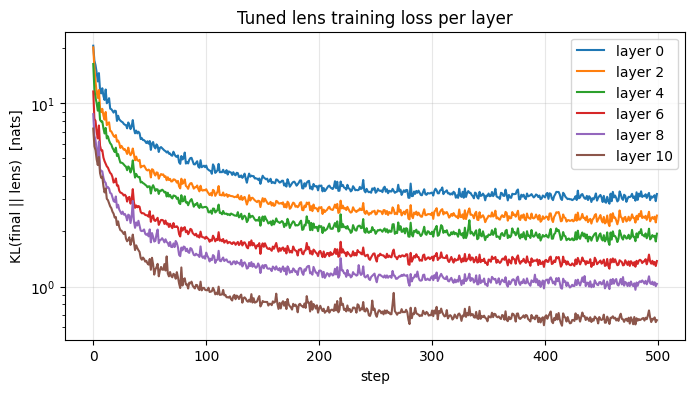

In [22]:
hist = np.array(history)
plt.figure(figsize=(8, 4))
for l in range(0, L, max(1, L // 6)):
    plt.plot(hist[:, l], label=f"layer {l}")
plt.yscale("log"); plt.xlabel("step"); plt.ylabel("KL(final || lens)  [nats]")
plt.title("Tuned lens training loss per layer"); plt.legend(); plt.grid(alpha=.3); plt.show()

In [ ]:
@torch.no_grad()
def evaluate(chunks, n_batches=30, bs=16):
    LN2 = math.log(2)
    kl = {"logit": np.zeros(L), "tuned": np.zeros(L)}
    ce = {"logit": np.zeros(L), "tuned": np.zeros(L)}
    ce_model, count = 0.0, 0
    for b in range(n_batches):
        batch = chunks[b * bs:(b + 1) * bs].to(device)
        if len(batch) == 0: break
        residuals, final_logits = run_with_residuals(model, batch)
        targets = batch[:, 1:].reshape(-1)
        ce_model += F.cross_entropy(final_logits[:, :-1].reshape(-1, final_logits.size(-1)), targets).item()
        for l, h in enumerate(residuals):
            for name, fn in [("logit", lambda h, l: logit_lens(h)), ("tuned", tuned_lens)]:
                lg = fn(h, l).float()
                kl[name][l] += kl_final_vs_lens(final_logits, lg).item()
                ce[name][l] += F.cross_entropy(lg[:, :-1].reshape(-1, lg.size(-1)), targets).item()
        count += 1
    for d_ in (kl, ce):
        for k in d_: d_[k] = d_[k] / count / LN2
    return kl, ce, ce_model / count / LN2

kl_eval, ce_eval, ce_model = evaluate(test_chunks)
print(f"{'layer':>5} | {'KL logit':>9} {'KL tuned':>9} | {'CE logit':>9} {'CE tuned':>9}   (bits)")
for l in range(L):
    print(f"{l:5d} | {kl_eval['logit'][l]:9.3f} {kl_eval['tuned'][l]:9.3f} | {ce_eval['logit'][l]:9.3f} {ce_eval['tuned'][l]:9.3f}")
print(f"model final cross-entropy: {ce_model:.3f} bits")

In [ ]:
# c = 0
# for i in model.parameters():
#   if len(i.shape)==2:
#     k = i.shape[0]*i.shape[1]
#   else:
#     k = i.shape[0]
#   c += k
#   print(len(i), i.shape)

In [ ]:
# n_params = sum(p.numel() for p in model.parameters())
# n_params

In [ ]:
c

In [ ]:
# !pip install -q tuned-lens

In [ ]:
# import torch
# from transformers import AutoModelForCausalLM, AutoTokenizer
# from tuned_lens.nn.lenses import TunedLens, LogitLens
# from tuned_lens.plotting import PredictionTrajectory

In [ ]:
# device = "cuda" if torch.cuda.is_available() else "cpu"
# print(device)
# name = "EleutherAI/pythia-160m-deduped"   # or "gpt2"

In [ ]:
# model = AutoModelForCausalLM.from_pretrained(name).to(device)
# tokenizer = AutoTokenizer.from_pretrained(name)

# tuned_lens = TunedLens.from_model_and_pretrained(model).to(device)  # downloads the pretrained lens
# logit_lens = LogitLens.from_model(model)

In [ ]:
# text = "The capital of France is Paris, and the capital of Germany is Berlin."
# input_ids = tokenizer.encode(text)
# targets = input_ids[1:] + [tokenizer.eos_token_id]

# for lens, title in [(logit_lens, "Logit Lens"), (tuned_lens, "Tuned Lens")]:
#     traj = PredictionTrajectory.from_lens_and_model(
#         lens=lens, model=model, input_ids=input_ids,
#         tokenizer=tokenizer, targets=targets,
#     )
#     traj.slice_sequence(slice(0, 20)).cross_entropy().figure(title=title).show()

In [ ]:
# Implementing Logits Lens

# Implementing Logit Lens

In [ ]:
# !pip install -q tuned-lens

In [ ]:
# import torch
# from transformers import AutoModelForCausalLM, AutoTokenizer
# from tuned_lens.nn.lenses import TunedLens, LogitLens
# from tuned_lens.plotting import PredictionTrajectory
# # from tuned_lens.nn.lenses import TunedLens, LogitLens
# # from tuned_lens.plotting import PredictionTrajectory

In [ ]:
# device = "cuda" if torch.cuda.is_available() else "cpu"
# print(device)
# model_name = "EleutherAI/pythia-160m-deduped"

In [ ]:
# model = AutoModelForCausalLM.from_pretrained(model_name).to(device)
# tokenizer = AutoTokenizer.from_pretrained(model_name)

In [ ]:
# tuned_lens = TunedLens.from_model_and_pretrained(model).to(device)  # downloads the pretrained lens
# logit_lens = LogitLens.from_model(model)

In [ ]:
# text = "The capital of France is Paris, and the capital of Germany is Berlin."
# input_ids = tokenizer.encode(text)
# targets = input_ids[1:] + [tokenizer.eos_token_id]

# for lens, title in [(logit_lens, "Logit Lens"), (tuned_lens, "Tuned Lens")]:
#     traj = PredictionTrajectory.from_lens_and_model(
#         lens=lens, model=model, input_ids=input_ids,
#         tokenizer=tokenizer, targets=targets,
#     )
#     traj.slice_sequence(slice(0, 20)).cross_entropy().figure(title=title).show()

# Implementing from Scratch Using Pytorch Logit Lens